# **PART E — Logistic Regression and Binary Classification:**

## **Problem:**

This is your main classification assessment.
Dataset
We will use Scikit-learn's breast cancer dataset.
```py
from sklearn.datasets import 
load_breast_cancerdataset = load_breast_cancer()
X = dataset.data
y = dataset.target
```
The original dataset labels are:
- 0: Malignant.
- 1: Benign.
For this exercise, create a new binary target:
- 1: Malignant.
- 0: Benign.
This lets you practice choosing the positive class deliberately rather than blindly accepting the dataset's existing label encoding.

## **E1. Understand the dataset:**
1. Print the dataset shape.
2. Print the number of features.
3. Count positive and negative samples.
4. Check whether the classes are balanced.
5. Visualize at least two features.
Explain why this is a classification problem, not a regression problem.

## **E2. Implement sigmoid:**
Write:
```py
def sigmoid(z):    
    pass
```

Use:
$$
g(z)=\frac{1}{1+e^{-z}}
$$
Test the following:
```py
values = np.array([-10, -5, -1, 0, 1, 5, 10])
```
Plot the sigmoid curve.

Explain:
- Why does its output always lie between zero and one?
- What is its output when \(z=0\)?
- What happens for extremely positive values?
- What happens for extremely negative values?
Consider numerical stability when implementing it for large positive and negative values.

## **E3. Logistic prediction function:**
Implement:
$$
z=\vec w\cdot\vec x+b
$$
$$
f_{\vec w,b}(\vec x)=g(z)
$$
Your function should return a probability, not a class label.

Test with:
- Different weights.
- Different biases.
- At least three input samples.

## **E4. Logistic loss:**
Implement the loss function:
$$
L(f(x),y)=
-y\log(f(x))
-(1-y)\log(1-f(x))
$$
Test all four situations:
Actual	Predicted probability
1	0.99
1	0.01
0	0.99
0	0.01

Explain why predicting a very low probability for an actual positive class should result in a large loss.

## **E5. Complete logistic regression cost:**
Implement:
$$
J(\vec w,b)=\frac{1}{m}
\sum_{i=1}^{m}
L(f_{\vec w,b}(\vec x^{(i)}),y^{(i)})
$$
Requirements:
- Support multiple features.
- Use a loop.
- Avoid Scikit-learn for the cost calculation.
- Test several weight and bias combinations.

## **E6. Train using Scikit-learn:**
Now use:
```py
from sklearn.linear_model import LogisticRegression
```

Requirements:
1. Split the data into training and testing sets.
2. Scale features using a Pipeline or a scaler fitted only on training data.
3. Train the model.
4. Generate probability predictions.
5. Generate class predictions.
6. Calculate test accuracy.
Use a fixed random_state.

## **E7. Decision threshold:**
Do not rely exclusively on the default threshold.

Use the probabilities generated by your model and implement:
```py
def predict_class(probabilities, threshold):   
     pass
```


Experiment with thresholds:
```py
thresholds = [0.3, 0.5, 0.7]
```

Compare the resulting classifications.

Explain why changing the threshold changes the number of positive predictions.

## **Solution:**

### E1

In [3]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer

dataset = load_breast_cancer()

X = dataset.data
y_original = dataset.target

y = (y_original == 0).astype(int)

In [9]:
print("Dataset shape:", X.shape)
print("Number of features:", X.shape[1])

positive = np.sum(y == 1)
negative = np.sum(y == 0)

print("Positive samples (Malignant):", positive)
print("Negative samples (Benign):", negative)

print("Positive percentage:", round(positive / len(y) * 100, 2))
print("Negative percentage:", round(negative / len(y) * 100, 2))

Dataset shape: (569, 30)
Number of features: 30
Positive samples (Malignant): 212
Negative samples (Benign): 357
Positive percentage: 37.26
Negative percentage: 62.74


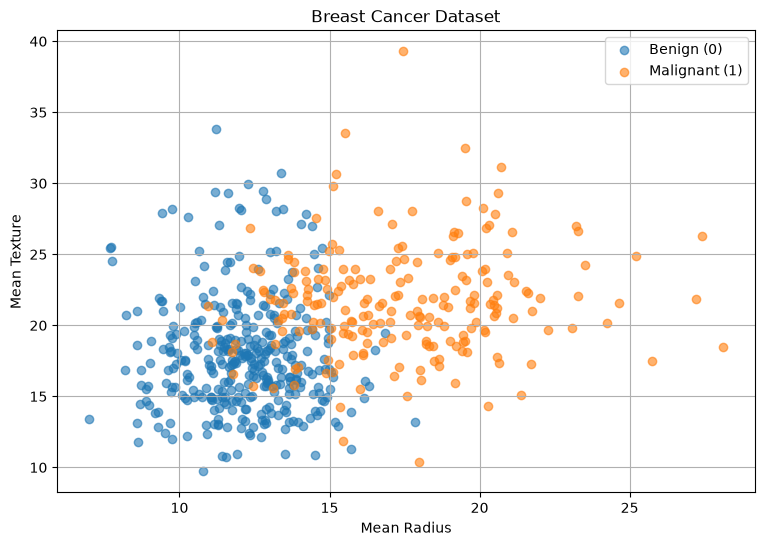

In [10]:
plt.figure(figsize=(9, 6))

plt.scatter(
    X[y == 0, 0],
    X[y == 0, 1],
    label="Benign (0)",
    alpha=0.6
)

plt.scatter(
    X[y == 1, 0],
    X[y == 1, 1],
    label="Malignant (1)",
    alpha=0.6
)

plt.xlabel("Mean Radius")
plt.ylabel("Mean Texture")
plt.title("Breast Cancer Dataset")
plt.legend()
plt.grid(True)
plt.show()

### E2

In [11]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

In [15]:
values = np.array([-10, -5, -1, 0, 1, 5, 10])

print(sigmoid(values))

[4.53978687e-05 6.69285092e-03 2.68941421e-01 5.00000000e-01
 7.31058579e-01 9.93307149e-01 9.99954602e-01]


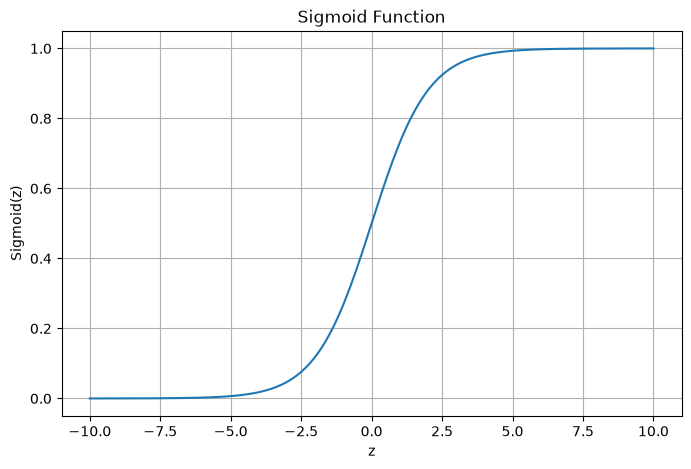

In [16]:
z = np.linspace(-10, 10, 200)

g = sigmoid(z)

plt.figure(figsize=(8, 5))

plt.plot(z, g)

plt.xlabel("z")
plt.ylabel("Sigmoid(z)")
plt.title("Sigmoid Function")

plt.grid(True)
plt.show()

### E3

In [17]:
def predict_probability(x, w, b):

    z = np.dot(x, w) + b

    return sigmoid(z)

In [18]:
X_demo = np.array([
    [0.5, 1.0],
    [1.5, -0.5],
    [-1.0, 2.0]
])

w = np.array([0.2, -0.1])
b = -0.5

probabilities = predict_probability(X_demo, w, b)

print(probabilities)

[0.37754067 0.46257015 0.2890505 ]


In [19]:
w1 = np.array([1.0, -0.5])
b1 = 0.0

w2 = np.array([-0.3, 0.8])
b2 = 0.4

print("First model:", predict_probability(X_demo, w1, b1))

print("Second model:", predict_probability(X_demo, w2, b2))

First model: [0.5        0.8519528  0.11920292]
Second model: [0.7407749  0.38936077 0.90887704]


### E4

In [21]:
def logistic_loss(y_true, y_prob):
    y_prob = np.clip(y_prob, 1e-15, 1 - 1e-15)

    loss = (
        -y_true * np.log(y_prob)
        -(1 - y_true) * np.log(1 - y_prob)
    )

    return loss

In [22]:
cases = [
    (1, 0.99),
    (1, 0.01),
    (0, 0.99),
    (0, 0.01)
]

for actual, probability in cases:

    loss = logistic_loss(actual, probability)

    print(
        f"Actual: {actual}, "
        f"Probability: {probability}, "
        f"Loss: {loss:.4f}"
    )

Actual: 1, Probability: 0.99, Loss: 0.0101
Actual: 1, Probability: 0.01, Loss: 4.6052
Actual: 0, Probability: 0.99, Loss: 4.6052
Actual: 0, Probability: 0.01, Loss: 0.0101


### E5

In [23]:
def compute_cost(x, y, w , b):
    m = x.shape[0]

    cost_sum = 0

    for i in range(m):
        z = np.dot(x[i], w) + b
        f_wb = sigmoid(z)

        loss = logistic_loss(y[i], f_wb)

        cost_sum += loss

    return cost_sum/(m)
        

In [26]:
X_demo = np.array([
    [0.2, -1.0, 0.5],
    [1.1, 0.3, -0.2],
    [-0.4, 0.8, 1.2],
    [0.7, -0.5, 0.1]
])

y_demo = np.array([1, 0, 1, 0])

# Different parameter combinations

w1 = np.array([0.0, 0.0, 0.0])
b1 = 0.0

w2 = np.array([0.4, -0.2, 0.1])
b2 = 0.1

w3 = np.array([-0.3, 0.5, 0.2])
b3 = -0.2

print("Cost 1:", compute_cost(X_demo, y_demo, w1, b1))

print("Cost 2:", compute_cost(X_demo, y_demo, w2, b2))

print("Cost 3:", compute_cost(X_demo, y_demo, w3, b3))

Cost 1: 0.6931471805599453
Cost 2: 0.7906779526834453
Cost 3: 0.6142539068182084


### E6

In [27]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

dataset = load_breast_cancer()

X = dataset.data
y_original = dataset.target

y = (y_original == 0).astype(int)

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42, test_size=0.2, stratify=y)

model = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("logistic", LogisticRegression(max_iter=5000))
    ]
)

model.fit(X_train, y_train)

y_prob = model.predict_proba(X_test)[:, 1]
print(y_prob[:10])

y_pred = model.predict(X_test)
print(y_pred[:10])

accuracy = accuracy_score(y_test, y_pred)

print("Test Accuracy:", accuracy)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

[3.64568116e-04 9.99999989e-01 4.25679471e-02 5.76187322e-01
 5.09155489e-01 6.16001620e-04 7.61534086e-01 1.01217174e-03
 5.68725516e-04 1.07675795e-02]
[0 1 0 1 1 0 1 0 0 0]
Test Accuracy: 0.9649122807017544
Confusion Matrix:
[[71  1]
 [ 3 39]]


### E7

In [28]:
def predict_class(probabilities, threshold):
    return (np.asarray(probabilities) >= threshold).astype(int)

In [30]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

thresholds = [0.3, 0.5, 0.7]

results = []

for threshold in thresholds:

    predictions = predict_class(y_prob, threshold)

    results.append({
        "Threshold": threshold,
        "Positive Predictions": np.sum(predictions == 1),
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions)
    })

threshold_results = pd.DataFrame(results)

print(threshold_results.to_string(index=False))

 Threshold  Positive Predictions  Accuracy  Precision   Recall  F1 Score
       0.3                    42  0.982456    0.97619 0.976190   0.97619
       0.5                    40  0.964912    0.97500 0.928571   0.95122
       0.7                    38  0.964912    1.00000 0.904762   0.95000
